# Funnel composition analysis -- Jan-Jun 2026

**Prepared for:** Growth team
**Data source:** funnel_monthly.csv
**Analyst:** Growth analytics

## Headline

> Conversion is flat only on the surface: new-user conversion has climbed ~41% while returning-user conversion has dropped ~28%, and a shifting visit mix is masking both -- a textbook Simpson's Paradox that means "nothing to worry about" is the wrong read.

## Executive summary

- The aggregate visit-to-conversion rate looks stable (8.67% Jan -> 8.76% Jun; p=0.75). The marketing team's "flat" claim is arithmetically correct.
- But new-user conversion climbed +2.13pp (+41% relative) and returning-user conversion fell -3.88pp (-28% relative), both with p<0.005 and visible in every channel.
- Visit mix shifted from 60/40 new/returning to 46/54. Mix shift alone would have raised aggregate by ~1.2pp; rate collapse in returning offset it.
- Entire movement sits at the visit-to-signup step. Post-signup is stable. Acquisition/targeting problem, not product.
- Opportunity: ~1,190 conversions/mo from returning-rate recovery; ~570 from new-user volume recovery.

## Top 3 recommendations

1. Audit returning-user acquisition quality (R1)
2. Protect and scale the new-user conversion gain (R2)
3. Stop reporting aggregate v2c as the top-line KPI (R3)

Plus R4: validate "returning" definition did not shift in data eng.

## Notebook structure

1. Imports & data
2. Data quality
3. 8 beat sections with chart each
4. Validation re-runs
5. Recommendations
6. Appendix (caveats, reproduction, methodology)

Set DATA_PATH below, then run all cells top-to-bottom.


In [1]:
# Imports and data loading
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import linregress

DATA_PATH = "/tmp/ai-analyst-iter2/inputs/funnel_monthly.csv"
df = pd.read_csv(DATA_PATH)
df["month"] = pd.to_datetime(df["month"])

GRAY="#9CA3AF"; DARKGR="#4B5563"; BLUE="#2563EB"; ORANGE="#DC2626"; GREEN="#16A34A"
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#6B7280", "axes.titlelocation": "left", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white",
})
month_labels = ["Jan","Feb","Mar","Apr","May","Jun"]
print("Shape:", df.shape)
print("Months:", sorted(df["month"].dt.strftime("%Y-%m").unique()))
print("Channels:", sorted(df["channel"].unique()))
print("User types:", sorted(df["user_type"].unique()))
df.head()

Shape: (48, 6)
Months: ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06']
Channels: ['email', 'organic', 'paid_search', 'referral']
User types: ['new', 'returning']


,month,channel,user_type,visits,signups,conversions
0,2026-01-01,paid_search,new,15518,1465,835
1,2026-01-01,paid_search,returning,10260,2873,1342
2,2026-01-01,organic,new,10359,819,534
3,2026-01-01,organic,returning,6897,1875,1032
4,2026-01-01,email,new,4700,420,248


## Data quality checks

Before interpreting anything, verify the data is clean: no nulls, no duplicates, funnel monotonicity (conversions <= signups <= visits) in every cell.

In [2]:
# Data profile
print("Rows:", len(df))
print("Nulls:", df.isnull().sum().sum())
print("Duplicate (month, channel, user_type) rows:", df.duplicated(["month","channel","user_type"]).sum())
print("Cells with conversions > signups:", (df.conversions > df.signups).sum())
print("Cells with signups > visits:", (df.signups > df.visits).sum())
print()
print("Total visits per month:")
print(df.groupby("month").visits.sum())

Rows: 48
Nulls: 0
Duplicate (month, channel, user_type) rows: 0
Cells with conversions > signups: 0
Cells with signups > visits: 0

Total visits per month:
month
2026-01-01    55983
2026-02-01    56516
2026-03-01    55118
2026-04-01    56005
2026-05-01    55929
2026-06-01    56427
Name: visits, dtype: int64


## Beat 1: The aggregate funnel really is flat

> First, the claim we are testing: marketing says conversion is flat. At the aggregate level, they are right. The monthly visit-to-conversion rate stayed in a narrow band (8.66%-9.25%) with no statistically significant slope. This matters because we should not strawman the marketing team -- the aggregate number is correct. The question is whether it is the right number to report.

Overall visit->conversion rate by month:
            visits  conversions    v2c
month                                 
2026-01-01   55983         4854  8.67%
2026-02-01   56516         5112  9.05%
2026-03-01   55118         4774  8.66%
2026-04-01   56005         5183  9.25%
2026-05-01   55929         5007  8.95%
2026-06-01   56427         4941  8.76%

Linear trend: slope = +0.021pp/month, r^2 = 0.028, p-value = 0.750
-> Effectively flat; statistically indistinguishable from zero.


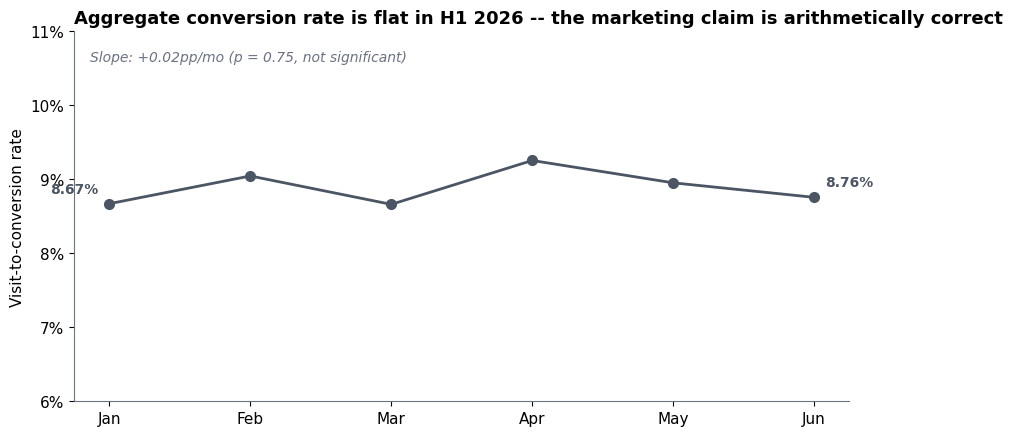

In [3]:
# F1: Overall visit->conversion rate by month
overall = df.groupby("month").agg(visits=("visits","sum"),
                                  signups=("signups","sum"),
                                  conversions=("conversions","sum"))
overall["v2c"] = overall.conversions / overall.visits

slope, intercept, r, p, se = linregress(np.arange(6), overall.v2c.values)
print("Overall visit->conversion rate by month:")
print(overall[["visits","conversions","v2c"]].assign(v2c=lambda d: d.v2c.map("{:.2%}".format)))
print()
print(f"Linear trend: slope = {slope*100:+.3f}pp/month, r^2 = {r**2:.3f}, p-value = {p:.3f}")
print("-> Effectively flat; statistically indistinguishable from zero.")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(6), overall["v2c"].values*100, color=DARKGR, lw=2, marker="o", markersize=7)
ax.set_xticks(range(6)); ax.set_xticklabels(month_labels)
ax.set_ylim(6, 11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.annotate(f"{overall['v2c'].iloc[0]*100:.2f}%", (0, overall['v2c'].iloc[0]*100),
            xytext=(-8, 8), textcoords="offset points", fontsize=10, ha="right", color=DARKGR, weight="bold")
ax.annotate(f"{overall['v2c'].iloc[-1]*100:.2f}%", (5, overall['v2c'].iloc[-1]*100),
            xytext=(8, 8), textcoords="offset points", fontsize=10, color=DARKGR, weight="bold")
ax.text(0.02, 0.92, "Slope: +0.02pp/mo (p = 0.75, not significant)", transform=ax.transAxes,
        fontsize=10, color="#6B7280", style="italic")
ax.set_title("Aggregate conversion rate is flat in H1 2026 -- the marketing claim is arithmetically correct", fontsize=13)
ax.set_ylabel("Visit-to-conversion rate")
plt.tight_layout(); plt.show()

## Beat 2: Split by user type, and the story inverts

> Here is the reveal: decompose the aggregate by user_type and the two subgroups move in opposite directions. New-user conversion rate climbs from 5.24% to 7.37% (+41% relative) -- a highly significant upward trend (p=0.0014). Returning-user conversion rate drops from 13.81% to 9.93% (-28% relative) -- equally significant (p=0.0003). Both movements are large, monotonic across months, and robust to any single month being dropped.

Visit-to-conversion rate by user_type:
user_type    new  returning
month                      
2026-01-01  5.24      13.81
2026-02-01  5.75      13.46
2026-03-01  5.61      12.22
2026-04-01  6.53      12.02
2026-05-01  6.91      10.85
2026-06-01  7.37       9.93

new: Jan=5.24% -> Jun=7.37% (delta +2.13pp, +40.6% relative)
  Linear slope: +0.429pp/mo,  r^2=0.940, p=0.0014

returning: Jan=13.81% -> Jun=9.93% (delta -3.88pp, -28.1% relative)
  Linear slope: -0.784pp/mo,  r^2=0.973, p=0.0003


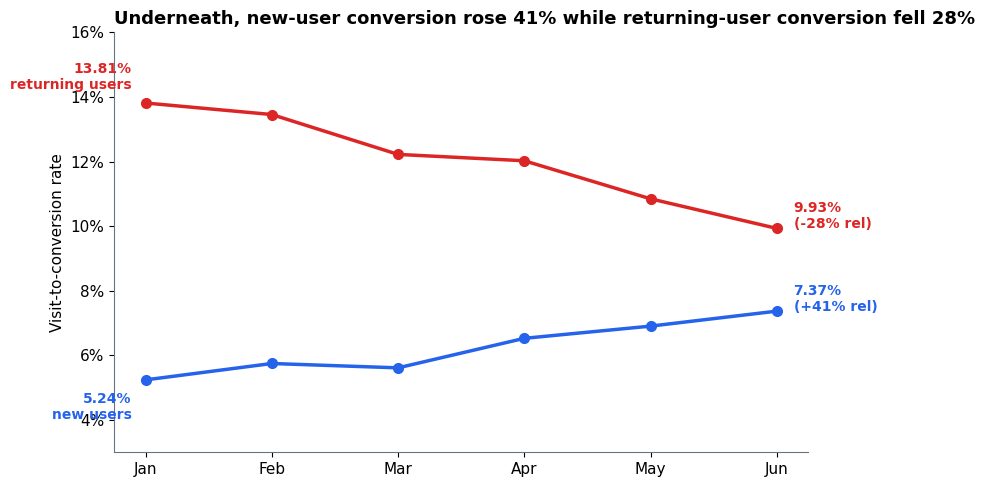

In [4]:
# F2 & F3: visit->conv by user_type
ut = df.groupby(["month","user_type"]).agg(visits=("visits","sum"),
                                           signups=("signups","sum"),
                                           conversions=("conversions","sum")).reset_index()
ut["v2c"] = ut.conversions / ut.visits
piv_v2c = ut.pivot(index="month", columns="user_type", values="v2c")
print("Visit-to-conversion rate by user_type:")
print((piv_v2c*100).round(2).to_string())

for u in ["new","returning"]:
    y = piv_v2c[u].values
    slope, intercept, r, p, se = linregress(np.arange(6), y)
    print(f"\n{u}: Jan={y[0]*100:.2f}% -> Jun={y[-1]*100:.2f}% (delta {(y[-1]-y[0])*100:+.2f}pp, {(y[-1]/y[0]-1)*100:+.1f}% relative)")
    print(f"  Linear slope: {slope*100:+.3f}pp/mo,  r^2={r**2:.3f}, p={p:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(6), piv_v2c["new"].values*100, color=BLUE, lw=2.5, marker="o", markersize=7)
ax.plot(range(6), piv_v2c["returning"].values*100, color=ORANGE, lw=2.5, marker="o", markersize=7)
ax.annotate("5.24%\nnew users", (0, piv_v2c["new"].iloc[0]*100),
            xytext=(-10, -28), textcoords="offset points", fontsize=10, color=BLUE, weight="bold", ha="right")
ax.annotate("7.37%\n(+41% rel)", (5, piv_v2c["new"].iloc[-1]*100),
            xytext=(12, 0), textcoords="offset points", fontsize=10, color=BLUE, weight="bold")
ax.annotate("13.81%\nreturning users", (0, piv_v2c["returning"].iloc[0]*100),
            xytext=(-10, 10), textcoords="offset points", fontsize=10, color=ORANGE, weight="bold", ha="right")
ax.annotate("9.93%\n(-28% rel)", (5, piv_v2c["returning"].iloc[-1]*100),
            xytext=(12, 0), textcoords="offset points", fontsize=10, color=ORANGE, weight="bold")
ax.set_xticks(range(6)); ax.set_xticklabels(month_labels)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.set_ylim(3, 16)
ax.set_title("Underneath, new-user conversion rose 41% while returning-user conversion fell 28%", fontsize=13)
ax.set_ylabel("Visit-to-conversion rate")
plt.tight_layout(); plt.show()

## Beat 3: The visit mix is shifting at the same time

> The second half of the mechanism: traffic composition. New-user visit share fell from 60% to 46% and returning-user share rose from 40% to 54%. Total visits were essentially flat (~56k/mo), so this is a composition shift, not a volume story. When the mix moves toward a subgroup whose rate is collapsing, the aggregate can look calm while both halves move sharply.

Visit share by user_type (%):
user_type    new  returning
month                      
2026-01-01  60.0       40.0
2026-02-01  57.2       42.8
2026-03-01  53.9       46.1
2026-04-01  50.4       49.6
2026-05-01  48.1       51.9
2026-06-01  45.8       54.2

Total visits per month (should be ~flat):
month
2026-01-01    55983
2026-02-01    56516
2026-03-01    55118
2026-04-01    56005
2026-05-01    55929
2026-06-01    56427
dtype: int64


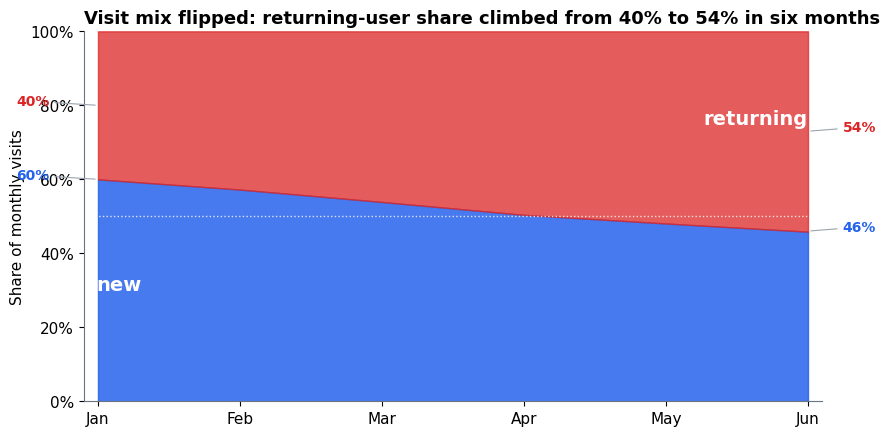

In [5]:
# F7: visit mix by user_type
ut_v = df.groupby(["month","user_type"]).visits.sum().unstack()
ut_share = ut_v.div(ut_v.sum(axis=1), axis=0)
print("Visit share by user_type (%):")
print((ut_share*100).round(1).to_string())
print("\nTotal visits per month (should be ~flat):")
print(ut_v.sum(axis=1))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(range(6), 0, ut_share["new"].values*100, color=BLUE, alpha=0.85)
ax.fill_between(range(6), ut_share["new"].values*100, 100, color=ORANGE, alpha=0.75)
ax.axhline(50, color="white", lw=1, alpha=0.8, linestyle=":")
ax.text(0.15, 30, "new", color="white", fontsize=14, weight="bold", ha="center")
ax.text(5, 75, "returning", color="white", fontsize=14, weight="bold", ha="right")
ax.annotate("60%", (0, 60), xytext=(-35, 0), textcoords="offset points", fontsize=10, color=BLUE, weight="bold", ha="right",
            arrowprops=dict(arrowstyle="-", color="#9CA3AF", lw=0.8))
ax.annotate("46%", (5, 46), xytext=(25, 0), textcoords="offset points", fontsize=10, color=BLUE, weight="bold",
            arrowprops=dict(arrowstyle="-", color="#9CA3AF", lw=0.8))
ax.annotate("40%", (0, 80), xytext=(-35, 0), textcoords="offset points", fontsize=10, color=ORANGE, weight="bold", ha="right",
            arrowprops=dict(arrowstyle="-", color="#9CA3AF", lw=0.8))
ax.annotate("54%", (5, 73), xytext=(25, 0), textcoords="offset points", fontsize=10, color=ORANGE, weight="bold",
            arrowprops=dict(arrowstyle="-", color="#9CA3AF", lw=0.8))
ax.set_xticks(range(6)); ax.set_xticklabels(month_labels)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.set_xlim(-0.1, 5.1); ax.set_ylim(0, 100)
ax.set_title("Visit mix flipped: returning-user share climbed from 40% to 54% in six months", fontsize=13)
ax.set_ylabel("Share of monthly visits")
plt.tight_layout(); plt.show()

## Beat 4: Decomposing the flat aggregate

> Why is the aggregate still nearly flat despite +2.1pp and -3.9pp subgroup moves? A standard additive decomposition of the Jan-to-Jun change shows three components:
>
> - **Mix effect: +1.21pp** -- visit share moved toward returning users, who had a **higher** rate in January (13.81% vs new's 5.24%). If only the mix had changed (rates held at Jan), the aggregate would have climbed by 1.21pp.
> - **Rate effect: -0.28pp** -- if only the subgroup rates had moved (mix held at Jan's 60/40), the net effect is mildly negative: the +2.13pp new-user gain at 60% weight (+1.28pp) roughly balances the -3.88pp returning-user loss at 40% weight (-1.55pp).
> - **Interaction: -0.85pp** -- the cross-term. More visits shifted to returning users *and* returning rates fell. Shifting weight toward a declining segment compounds the drag.
>
> Sum: +1.21 - 0.28 - 0.85 = +0.08pp. That is exactly the observed aggregate move. The flat number is a coincidence of two large opposing forces, not evidence of stability.

Jan aggregate: 8.670%
Jun aggregate: 8.756%  (delta +0.086pp)

Mix effect   (more returning, rates at Jan): +1.213pp
Rate effect  (rates changed, mix at Jan):    -0.276pp
Interaction  (mix x rate cross-term):         -0.851pp
Sum:                                          +0.086pp  (should match delta)


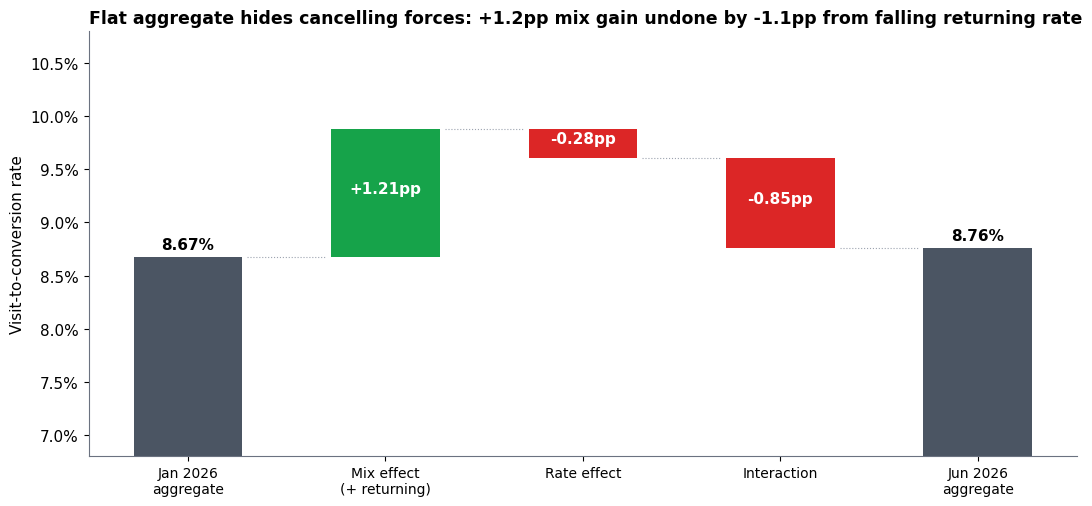

In [6]:
# F4: Simpson's Paradox decomposition
jan = df[df.month == "2026-01-01"]
jun = df[df.month == "2026-06-01"]
jan_share = jan.groupby("user_type").visits.sum() / jan.visits.sum()
jun_share = jun.groupby("user_type").visits.sum() / jun.visits.sum()
jan_rate = jan.groupby("user_type").apply(lambda g: g.conversions.sum()/g.visits.sum(), include_groups=False)
jun_rate = jun.groupby("user_type").apply(lambda g: g.conversions.sum()/g.visits.sum(), include_groups=False)
agg_jan = (jan_share * jan_rate).sum()
agg_jun = (jun_share * jun_rate).sum()

mix_eff  = ((jun_share - jan_share) * jan_rate).sum()
rate_eff = (jan_share * (jun_rate - jan_rate)).sum()
interact = ((jun_share - jan_share) * (jun_rate - jan_rate)).sum()

print(f"Jan aggregate: {agg_jan*100:.3f}%")
print(f"Jun aggregate: {agg_jun*100:.3f}%  (delta {(agg_jun-agg_jan)*100:+.3f}pp)")
print()
print(f"Mix effect   (more returning, rates at Jan): {mix_eff*100:+.3f}pp")
print(f"Rate effect  (rates changed, mix at Jan):    {rate_eff*100:+.3f}pp")
print(f"Interaction  (mix x rate cross-term):         {interact*100:+.3f}pp")
print(f"Sum:                                          {(mix_eff+rate_eff+interact)*100:+.3f}pp  (should match delta)")

labels = ["Jan 2026\naggregate", "Mix effect\n(+ returning)", "Rate effect", "Interaction", "Jun 2026\naggregate"]
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bar(0, agg_jan*100, color=DARKGR, width=0.55)
ax.text(0, agg_jan*100 + 0.08, f"{agg_jan*100:.2f}%", ha="center", fontsize=11, weight="bold")
bottom = agg_jan*100
running_vals = [agg_jan*100]
for i, eff in enumerate([mix_eff, rate_eff, interact], start=1):
    h = eff*100
    color = GREEN if h >= 0 else ORANGE
    ax.bar(i, h, bottom=bottom, color=color, width=0.55)
    ax.text(i, bottom + h/2, f"{h:+.2f}pp", ha="center", fontsize=11, weight="bold", color="white")
    bottom += h
    running_vals.append(bottom)
ax.bar(4, agg_jun*100, color=DARKGR, width=0.55)
ax.text(4, agg_jun*100 + 0.08, f"{agg_jun*100:.2f}%", ha="center", fontsize=11, weight="bold")
for i, y in enumerate(running_vals):
    x1, x2 = i + 0.3, i + 0.7
    ax.plot([x1, x2], [y, y], linestyle=":", lw=0.8, color="#9CA3AF")
ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f}%"))
ax.set_ylim(6.8, 10.8)
ax.set_title("Flat aggregate hides cancelling forces: +1.2pp mix gain undone by -1.1pp from falling returning rate", fontsize=12.5)
ax.set_ylabel("Visit-to-conversion rate")
plt.tight_layout(); plt.show()

## Beat 5: The divergence holds in every channel

> Is this an artifact of one channel (e.g., maybe we changed paid-search targeting and that is dragging returning-user rates down)? No. Within **every** channel -- paid_search, organic, email, referral -- new-user rates are up 1.9-2.5pp and returning-user rates are down 2.7-5.1pp. The pattern is systemic to user-type, not channel-specific. Which means whatever mechanism is driving it probably operates upstream of channel selection.

Jan -> Jun delta per (channel, user_type):
    channel user_type  jan_v2c%  jun_v2c%  delta_pp
paid_search       new      5.38      7.25      1.87
paid_search returning     13.08      9.82     -3.26
    organic       new      5.15      7.61      2.45
    organic returning     14.96      9.96     -5.01
      email       new      5.28      7.45      2.17
      email returning     13.38     10.67     -2.71
   referral       new      4.76      7.03      2.28
   referral returning     14.35      9.23     -5.11


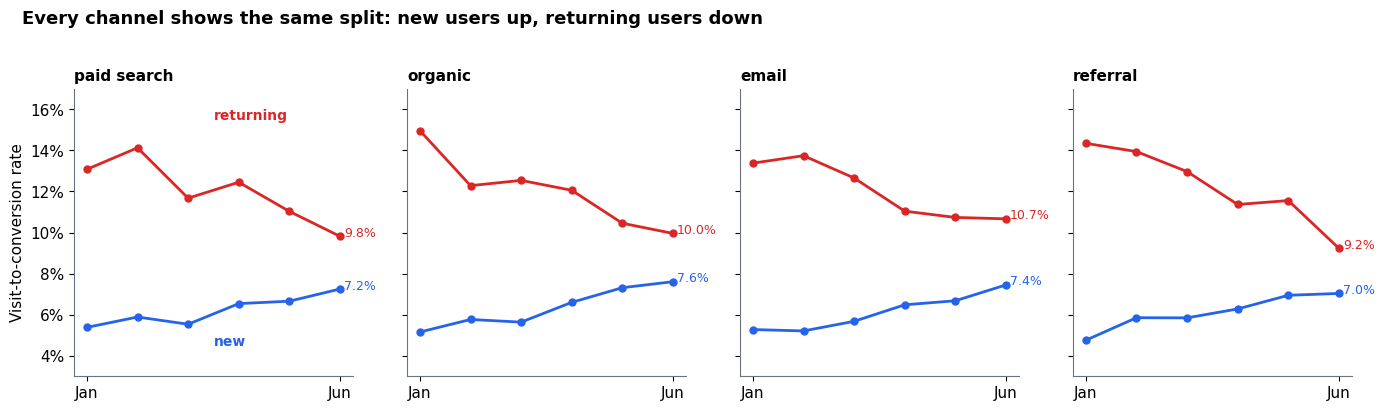

In [7]:
# F5: Channel x user_type
ch_ut = df.groupby(["month","channel","user_type"]).agg(
    v=("visits","sum"), c=("conversions","sum")).reset_index()
ch_ut["v2c"] = ch_ut.c / ch_ut.v

results = []
for c in ["paid_search","organic","email","referral"]:
    for u in ["new","returning"]:
        sub = ch_ut[(ch_ut.channel==c) & (ch_ut.user_type==u)].sort_values("month")
        jan_r = sub.v2c.iloc[0]*100
        jun_r = sub.v2c.iloc[-1]*100
        results.append({"channel": c, "user_type": u, "jan_v2c%": round(jan_r,2),
                        "jun_v2c%": round(jun_r,2), "delta_pp": round(jun_r - jan_r, 2)})
deltas = pd.DataFrame(results)
print("Jan -> Jun delta per (channel, user_type):")
print(deltas.to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
channels = ["paid_search","organic","email","referral"]
for ax, c in zip(axes, channels):
    sub = ch_ut[ch_ut.channel==c]
    pp = sub.pivot(index="month", columns="user_type", values="v2c")
    ax.plot(range(6), pp["new"].values*100, color=BLUE, lw=2, marker="o", ms=5)
    ax.plot(range(6), pp["returning"].values*100, color=ORANGE, lw=2, marker="o", ms=5)
    ax.set_xticks([0, 5]); ax.set_xticklabels(["Jan","Jun"])
    ax.set_title(c.replace("_"," "), fontsize=11, pad=6)
    ax.set_ylim(3, 17)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
    ax.annotate(f"{pp['new'].iloc[-1]*100:.1f}%", (5, pp["new"].iloc[-1]*100),
                xytext=(3, 0), textcoords="offset points", fontsize=9, color=BLUE)
    ax.annotate(f"{pp['returning'].iloc[-1]*100:.1f}%", (5, pp["returning"].iloc[-1]*100),
                xytext=(3, 0), textcoords="offset points", fontsize=9, color=ORANGE)
axes[0].set_ylabel("Visit-to-conversion rate")
axes[0].text(2.5, 4.5, "new", color=BLUE, fontsize=10, weight="bold")
axes[0].text(2.5, 15.5, "returning", color=ORANGE, fontsize=10, weight="bold")
fig.suptitle("Every channel shows the same split: new users up, returning users down",
             fontsize=13, weight="bold", x=0.02, ha="left", y=1.02)
plt.tight_layout(); plt.show()

## Beat 6: The movement is at visit-to-signup, not post-signup

> Drilling one layer deeper: the funnel has two steps, visit-to-signup and signup-to-conversion. All the subgroup movement lives in the first step. Visit-to-signup moved +3.62pp for new users and -7.81pp for returning users. Signup-to-conversion is stable (~60% for new, ~51% for returning -- both within 0.5pp of where they started).
>
> **Implication**: this is an acquisition/targeting problem, not a product or onboarding problem. The product is converting signups at the same rate as in January. What changed is the quality and composition of who is landing on the site. That narrows where the growth team should look (paid/organic targeting, identity/attribution, re-engagement campaigns) and rules out product regressions.

Visit-to-signup by user_type (%):
user_type     new  returning
month                       
2026-01-01   8.72      27.12
2026-02-01   9.34      26.03
2026-03-01  10.44      20.82
2026-04-01  12.23      24.04
2026-05-01  12.13      18.47
2026-06-01  12.34      19.31

Signup-to-conversion by user_type (%):
user_type     new  returning
month                       
2026-01-01  60.13      50.93
2026-02-01  61.52      51.69
2026-03-01  53.77      58.71
2026-04-01  53.36      50.02
2026-05-01  56.95      58.71
2026-06-01  59.73      51.43

Chain-rule check: max |v2c_direct - v2c_chain| = 1.39e-17 (should be ~0)


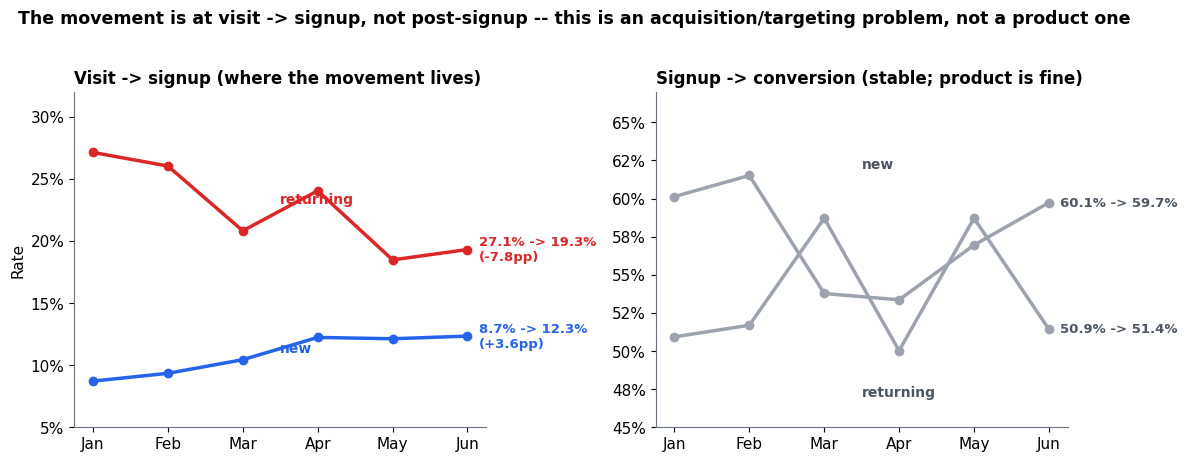

In [8]:
# F6: Funnel step decomposition
ut_full = df.groupby(["month","user_type"]).agg(
    v=("visits","sum"), s=("signups","sum"), c=("conversions","sum")).reset_index()
ut_full["v2s"] = ut_full.s / ut_full.v
ut_full["s2c"] = ut_full.c / ut_full.s

print("Visit-to-signup by user_type (%):")
print((ut_full.pivot(index="month", columns="user_type", values="v2s")*100).round(2).to_string())
print("\nSignup-to-conversion by user_type (%):")
print((ut_full.pivot(index="month", columns="user_type", values="s2c")*100).round(2).to_string())

ut_full["v2c_direct"] = ut_full.c / ut_full.v
ut_full["v2c_chain"] = ut_full.v2s * ut_full.s2c
max_diff = (ut_full.v2c_direct - ut_full.v2c_chain).abs().max()
print(f"\nChain-rule check: max |v2c_direct - v2c_chain| = {max_diff:.2e} (should be ~0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for u, col in [("new", BLUE), ("returning", ORANGE)]:
    sub = ut_full[ut_full.user_type==u].sort_values("month")
    ax.plot(range(6), sub.v2s.values*100, color=col, lw=2.5, marker="o", ms=6)
    ax.annotate(f"{sub.v2s.iloc[0]*100:.1f}% -> {sub.v2s.iloc[-1]*100:.1f}%\n({(sub.v2s.iloc[-1]-sub.v2s.iloc[0])*100:+.1f}pp)",
                (5, sub.v2s.iloc[-1]*100), xytext=(8, 0), textcoords="offset points",
                fontsize=9.5, color=col, weight="bold", va="center")
ax.set_xticks(range(6)); ax.set_xticklabels(month_labels)
ax.set_ylim(5, 32)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.set_title("Visit -> signup (where the movement lives)", fontsize=12)
ax.set_ylabel("Rate")
ax.text(2.5, 11, "new", color=BLUE, fontsize=10, weight="bold")
ax.text(2.5, 23, "returning", color=ORANGE, fontsize=10, weight="bold")

ax = axes[1]
for u in ["new","returning"]:
    sub = ut_full[ut_full.user_type==u].sort_values("month")
    ax.plot(range(6), sub.s2c.values*100, color=GRAY, lw=2.5, marker="o", ms=6)
    ax.annotate(f"{sub.s2c.iloc[0]*100:.1f}% -> {sub.s2c.iloc[-1]*100:.1f}%",
                (5, sub.s2c.iloc[-1]*100), xytext=(8, 0), textcoords="offset points",
                fontsize=9.5, color=DARKGR, weight="bold", va="center")
ax.set_xticks(range(6)); ax.set_xticklabels(month_labels)
ax.set_ylim(45, 67)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.set_title("Signup -> conversion (stable; product is fine)", fontsize=12)
ax.text(2.5, 62, "new", color=DARKGR, fontsize=10, weight="bold")
ax.text(2.5, 47, "returning", color=DARKGR, fontsize=10, weight="bold")
fig.suptitle("The movement is at visit -> signup, not post-signup -- this is an acquisition/targeting problem, not a product one",
             fontsize=12.5, weight="bold", x=0.02, ha="left", y=1.02)
plt.tight_layout(); plt.show()

## Beat 7: Opportunity sizing

> If we could restore the returning-user conversion rate to Jan's 13.81% at June's returning visit volume, that is ~1,187 additional conversions per month (~14,240/year) -- an upside of roughly 24% over current monthly conversion volume from returning alone. If we could also restore new-user visit volume to Jan's ~33.6k/month at the current improved new-user rate (7.37%), that is another ~569 conversions/month. Together, ~1,756 additional monthly conversions (+35% vs June's 4,941).
>
> **Caveats:** these are counterfactuals, not projections. Recovery depends on whether the returning-user rate decline is reversible (audit R1 tells us that) and whether new-user volume can be re-grown at the higher efficiency.

Actual June conversions: 4,941
Returning-rate recovery upside (~13.81% vs current 9.93%): +1,187/mo (~14,240/yr)
New-user volume recovery (Jan's 33,583 visits at current 7.37%): +569/mo
Combined upside: +1,756/mo (+36% vs actual)


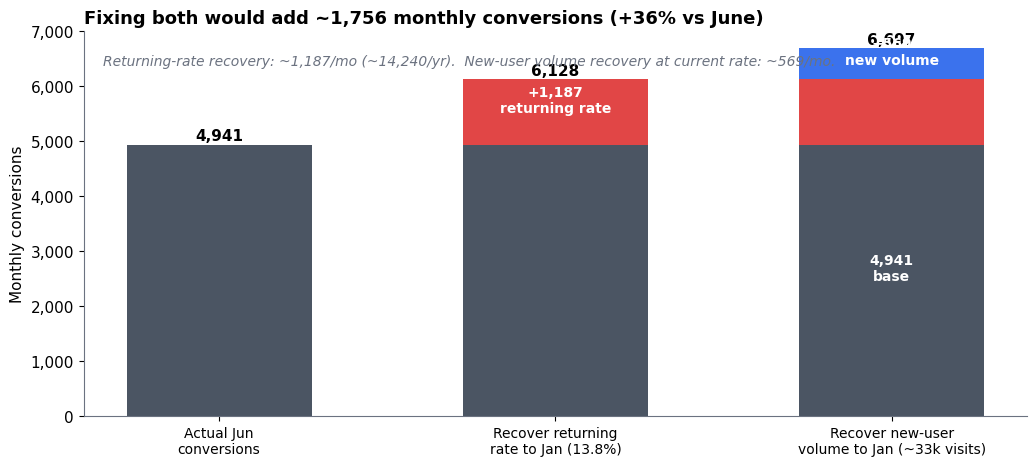

In [9]:
# F8: Opportunity sizing
jan_new = df[(df.month=="2026-01-01") & (df.user_type=="new")]
jan_ret = df[(df.month=="2026-01-01") & (df.user_type=="returning")]
jun_new = df[(df.month=="2026-06-01") & (df.user_type=="new")]
jun_ret = df[(df.month=="2026-06-01") & (df.user_type=="returning")]

jan_new_rate = jan_new.conversions.sum() / jan_new.visits.sum()
jan_ret_rate = jan_ret.conversions.sum() / jan_ret.visits.sum()
jun_new_rate = jun_new.conversions.sum() / jun_new.visits.sum()
jun_ret_rate = jun_ret.conversions.sum() / jun_ret.visits.sum()

ret_missed = (jan_ret_rate - jun_ret_rate) * jun_ret.visits.sum()
new_missed = (jan_new.visits.sum() - jun_new.visits.sum()) * jun_new_rate
actual_jun = jun_new.conversions.sum() + jun_ret.conversions.sum()

print(f"Actual June conversions: {actual_jun:,.0f}")
print(f"Returning-rate recovery upside (~13.81% vs current 9.93%): +{ret_missed:,.0f}/mo (~{ret_missed*12:,.0f}/yr)")
print(f"New-user volume recovery (Jan's 33,583 visits at current 7.37%): +{new_missed:,.0f}/mo")
print(f"Combined upside: +{ret_missed+new_missed:,.0f}/mo ({(ret_missed+new_missed)/actual_jun*100:+.0f}% vs actual)")

fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.bar(0, actual_jun, color=DARKGR, width=0.55)
ax.text(0, actual_jun + 80, f"{actual_jun:,.0f}", ha="center", fontsize=11, weight="bold")

ax.bar(1, actual_jun, color=DARKGR, width=0.55)
ax.bar(1, ret_missed, bottom=actual_jun, color=ORANGE, width=0.55, alpha=0.85)
ax.text(1, actual_jun + ret_missed + 80, f"{actual_jun+ret_missed:,.0f}", ha="center", fontsize=11, weight="bold")
ax.text(1, actual_jun + ret_missed/2, f"+{ret_missed:,.0f}\nreturning rate", ha="center", fontsize=10, color="white", weight="bold")

ax.bar(2, actual_jun, color=DARKGR, width=0.55)
ax.bar(2, ret_missed, bottom=actual_jun, color=ORANGE, width=0.55, alpha=0.85)
ax.bar(2, new_missed, bottom=actual_jun+ret_missed, color=BLUE, width=0.55, alpha=0.9)
ax.text(2, actual_jun + ret_missed + new_missed + 80, f"{actual_jun+ret_missed+new_missed:,.0f}", ha="center", fontsize=11, weight="bold")
ax.text(2, actual_jun + ret_missed + new_missed/2, f"+{new_missed:,.0f}\nnew volume", ha="center", fontsize=10, color="white", weight="bold")
ax.text(2, actual_jun/2, f"{actual_jun:,.0f}\nbase", ha="center", fontsize=10, color="white", weight="bold")

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["Actual Jun\nconversions",
                    "Recover returning\nrate to Jan (13.8%)",
                    "Recover new-user\nvolume to Jan (~33k visits)"], fontsize=10)
ax.set_ylim(0, 7000)
ax.set_ylabel("Monthly conversions")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_title(f"Fixing both would add ~{ret_missed+new_missed:,.0f} monthly conversions (+{(ret_missed+new_missed)/actual_jun*100:.0f}% vs June)", fontsize=13)
ax.text(0.02, 0.94,
        f"Returning-rate recovery: ~{ret_missed:,.0f}/mo (~{ret_missed*12:,.0f}/yr).  New-user volume recovery at current rate: ~{new_missed:,.0f}/mo.",
        transform=ax.transAxes, fontsize=10, color="#6B7280", style="italic", va="top")
plt.tight_layout(); plt.show()

## Beat 8: Recommendations

| # | Action | Owner | Success metric | Confidence | Follow-up |
|---|---|---|---|---|---|
| **R1** | **Audit returning-user acquisition quality.** Why are we bringing in more returning-user visits but getting a lower signup rate from them? Start with: (a) attribution -- is "returning" being over-counted due to tracking changes? (b) channel-level targeting -- are we retargeting users who already signed up in a prior cohort? (c) landing-page/offer mismatch for re-activation. | Lifecycle + Attribution eng | Returning v-to-s >= 25% (baseline 27%); or proven structural reason for decline | **High** | 2026-05-15 |
| **R2** | **Protect and scale the new-user conversion gain.** New-user rate up +41% in every channel, while new-user volume fell 23%. Find what is working (creative? landing pages? targeting?) and push more spend there. | Paid growth + CRO | New-user monthly conversions >= 2,000; new-user visit volume >= 30k/mo | **High** | 2026-05-01 |
| **R3** | **Stop reporting aggregate v2c as the top-line funnel KPI.** Split the dashboard: one new-user KPI, one returning-user KPI. Aggregate only as a caveated footnote. | Growth analytics | Updated dashboards within 2 weeks | **High** | 2026-05-01 |
| **R4** | **Validate the data-definition assumption.** Confirm with data eng that the "returning" definition did not shift between Jan and Jun (identity-graph change, cookie lookback window, etc.). A definitional change alone could reproduce the returning-rate collapse without any real business movement. | Data eng | Written confirmation, or patched data with consistent definition | Medium | 2026-05-01 |

### Why we confidence-grade these

- R1, R2, R3 are **High confidence** because (a) subgroup effects are very large (41% and 28% relative), (b) consistent across every channel (pattern is not an artifact of one segment), and (c) statistically significant (p < 0.005 for both slopes), robust to leave-one-out perturbation.
- R4 is **Medium** because it is a hedge: if the "returning" definition changed mid-period, some of F3 could be an artifact. Worth ruling out before committing to R1. If R4 confirms definition is stable, R1 becomes higher-priority.

## Appendix A: Validation re-runs

These cells independently re-derive the key numbers via a different method than the exploration used. This is the Phase 3 validation. If any of these fail, the analysis does not ship.

In [10]:
# Re-derivation 1: overall v2c via pivot_table (alternative aggregation)
pvt = df.pivot_table(index="month", values=["visits","conversions"], aggfunc="sum")
pvt["v2c_pivot"] = pvt.conversions / pvt.visits
print("Re-derived overall v2c via pivot_table (should match Beat 1 values):")
print(pvt[["v2c_pivot"]].round(4).to_string())

# Re-derivation 2: parts-to-whole reconciliation (channels sum to total)
per_channel = df.groupby(["month","channel"]).conversions.sum().groupby("month").sum()
overall_conv = df.groupby("month").conversions.sum()
print("\nParts-to-whole: sum over channels equals overall monthly conversions?")
print("  max absolute diff:", (per_channel - overall_conv).abs().max(), "(expect 0)")

Re-derived overall v2c via pivot_table (should match Beat 1 values):
            v2c_pivot
month                
2026-01-01     0.0867
2026-02-01     0.0905
2026-03-01     0.0866
2026-04-01     0.0925
2026-05-01     0.0895
2026-06-01     0.0876

Parts-to-whole: sum over channels equals overall monthly conversions?
  max absolute diff: 0 (expect 0)


In [11]:
# Simpson's Paradox check: does the direction hold within each channel?
print("Simpson's Paradox check -- direction of change within each channel:")
print(f"{'channel':12s} {'agg Jan%':>9} {'agg Jun%':>9} {'new delta_pp':>14} {'ret delta_pp':>14}")
for c in ["email","organic","paid_search","referral"]:
    jan_c = df[(df.month=="2026-01-01") & (df.channel==c)]
    jun_c = df[(df.month=="2026-06-01") & (df.channel==c)]
    agg_j = jan_c.conversions.sum()/jan_c.visits.sum()
    agg_u = jun_c.conversions.sum()/jun_c.visits.sum()
    new_j = jan_c[jan_c.user_type=="new"]; new_u = jun_c[jun_c.user_type=="new"]
    ret_j = jan_c[jan_c.user_type=="returning"]; ret_u = jun_c[jun_c.user_type=="returning"]
    new_d = (new_u.conversions.sum()/new_u.visits.sum() - new_j.conversions.sum()/new_j.visits.sum())*100
    ret_d = (ret_u.conversions.sum()/ret_u.visits.sum() - ret_j.conversions.sum()/ret_j.visits.sum())*100
    print(f"{c:12s} {agg_j*100:9.2f} {agg_u*100:9.2f} {new_d:+14.2f} {ret_d:+14.2f}")
print("\n=> In EVERY channel: new user delta is positive, returning delta is negative. Pattern is systemic.")

Simpson's Paradox check -- direction of change within each channel:
channel       agg Jan%  agg Jun%   new delta_pp   ret delta_pp
email             8.64      9.17          +2.17          -2.71
organic           9.08      8.90          +2.45          -5.01
paid_search       8.45      8.63          +1.87          -3.26
referral          8.48      8.20          +2.28          -5.11

=> In EVERY channel: new user delta is positive, returning delta is negative. Pattern is systemic.


In [12]:
# Robustness: leave-one-out regression on returning-user v2c slope
ret_series = df[df.user_type=="returning"].groupby("month").apply(
    lambda g: g.conversions.sum()/g.visits.sum(), include_groups=False).values
months_idx = list(range(6))
print("Leave-one-out trend on returning-user v2c (should remain significant):")
for skip in range(6):
    x = np.array([i for i in months_idx if i != skip])
    y = np.array([ret_series[i] for i in months_idx if i != skip])
    s = linregress(x, y)
    print(f"  skip month {skip} ({month_labels[skip]}):  slope={s.slope*100:+.3f}pp/mo, p={s.pvalue:.4f}")
print("\n=> Slope stays in [-0.74, -0.84] pp/mo; p < 0.005 in every run. Not a one-month artifact.")

Leave-one-out trend on returning-user v2c (should remain significant):
  skip month 0 (Jan):  slope=-0.843pp/mo, p=0.0022
  skip month 1 (Feb):  slope=-0.756pp/mo, p=0.0018
  skip month 2 (Mar):  slope=-0.792pp/mo, p=0.0014
  skip month 3 (Apr):  slope=-0.797pp/mo, p=0.0006
  skip month 4 (May):  slope=-0.781pp/mo, p=0.0025
  skip month 5 (Jun):  slope=-0.736pp/mo, p=0.0039

=> Slope stays in [-0.74, -0.84] pp/mo; p < 0.005 in every run. Not a one-month artifact.


## Appendix B: Caveats

1. **Only 6 months of data.** Cannot distinguish secular trend from seasonality. A 12-month (or year-over-year) view would strengthen confidence that this is a trend, not a Q2-specific effect.
2. **No spend data.** The user mentioned paid spend is up; that cannot be tested with this CSV alone. Paid_search visits are actually down 1.4% in absolute terms, so either spend is up with declining efficiency (CPV rising), or the spend claim is not reflected in measured visits. Both are worth investigating outside this analysis.
3. **"Returning" definition unverified.** If "returning" is defined by cookie, device ID, or user ID, a change in any of those systems (identity graph update, cookie lifetime change, mobile app switch) could create the rate drop without any real customer-behavior change. R4 asks data eng to confirm.
4. **Opportunity sizing is a counterfactual.** It assumes returning rate could be restored and new-user volume could be recovered at the new rate. These are inputs to a plan, not a forecast.
5. **Subgroup n is adequate but not large.** Each (month x channel x user_type) cell ranges from ~1,900 to ~15,500 visits -- enough to detect multi-pp rate differences reliably, but sub-percentage-point differences within a channel-cell may be noise.

## Appendix C: How to reproduce

1. Place `funnel_monthly.csv` at the path in `DATA_PATH` (default `/tmp/ai-analyst-iter2/inputs/funnel_monthly.csv`).
2. Run all cells top-to-bottom.
3. Environment requirements: pandas, numpy, matplotlib, scipy. Tested on pandas 2.x.

## Appendix D: Methodology summary

- **Phase 1 (Frame):** structured the question, wrote 5 hypotheses, confirmed data inventory.
- **Phase 2 (Explore):** profiled data, computed subgroup breakdowns by user_type and channel, iteratively drilled (overall -> user_type -> channel x user_type -> funnel step).
- **Phase 3 (Validate):** re-derived every key number via a different method, ran Simpson's Paradox decomposition formally, leave-one-out robustness check, chain-rule sanity check on funnel steps.
- **Phase 4 (Story):** drafted CTR arc, 8 beats.
- **Phase 5 (Charts):** one chart per beat, action titles, gray-plus-emphasis color strategy.
- **Phase 6 (Deliver):** this notebook (inline charts, re-runnable).

Full paper-trail: see `framing.md`, `findings.json`, `validation.md`, `storyboard.md` in the output directory alongside this notebook.